In [36]:
import os
import random
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.lines as mlines
import networkx as nx

# Add project source to path
sys.path.append(
    os.path.join(
        '..',  # notes -> root
    )
)

from src.simulation import (
    build_graph,
    build_kernel_bank,
    assign_kernels,
    build_initial_state,
    heterogeneous_contagion_process,
    get_activations,
    simple_kernel
)
from src.inference.inference import (
    fit_stan,
    extract_kernel_summary,
    compute_model_comparison,
    get_posterior_draws,
    summarize_inference
)

random.seed(11)

In [37]:
# parameters
n = 256; avg_deg = 18
beta1 = 0.01; beta2 = 0.05
epsilon = 0.9; delta = 0.0
omega = 0.0
gamma = 0.1
rho = 0.125 # initial infected proportion
tmax = 1000

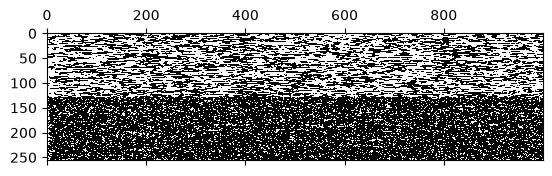

In [38]:
GRAPH = {"type": "sbm",
         "params": {"n": n, "avg_degree": avg_deg, "B": 2, "epsilon": epsilon, "delta": delta}}
A, kmax = build_graph(GRAPH)
KERNELS = [{"type": "simple", "beta": beta1},
           {"type": "simple", "beta": beta2}]
bank = build_kernel_bank(KERNELS, kmax)
ASSIGNMENT = {"mode": "block_flip", "omega": omega}
labels = assign_kernels(n, ASSIGNMENT, 2)
c  = np.stack([bank[labels[l]] for l in range(n)])
x0 = build_initial_state(n, rho)
x = heterogeneous_contagion_process(A, gamma, c, x0, tmax=tmax)
M, N = get_activations(np.transpose(x), A, kmax)

plt.spy(x.T)

In [39]:
fpath = "./posterior_mus.npy"
if not os.path.isfile(fpath): # skip running inference if posterior draws saved
    configf = '../configs/models/nonparametric_eb.yaml'
    res = fit_stan(M, N, configf, instance_params={"stan_file": '../src/models/mixture_nonparametric_eb.stan', "K": 1})
    mus = get_posterior_draws(res, "mu")
    np.save("posterior_mus.npy", mus[:, 0, :])

mus = np.load("posterior_mus.npy")
mu = np.mean(mus, axis=0); mu.shape # should be (kmax,)

(30,)

In [40]:
# compute 
L = M + N; L
mask = np.where(L > 0)
empirical_nus = np.stack([range(1, kmax+1)] * n)[mask].flatten()
empirical_infection = M[mask].flatten() / L[mask].flatten()

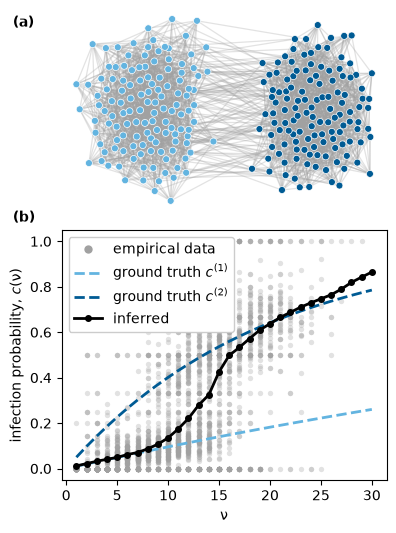

In [43]:
# figure geometry
PANEL_A_W = 3.25   # width  of panel (a) in inches
PANEL_A_H = 2.0    # height of panel (a)
PANEL_B_W = 3.25   # width  of panel (b)
PANEL_B_H = 2.50   # height of panel (b)

VSPACE    = 0.2   # vertical gap between panels (in inches)
LMARGIN   = 0.2   # left margin
RMARGIN   = 0.2   # right margin
TMARGIN   = 0.1   # top margin
BMARGIN   = 0.7   # bottom margin

fig_w = LMARGIN + max(PANEL_A_W, PANEL_B_W) + RMARGIN
fig_h = TMARGIN + PANEL_A_H + VSPACE + PANEL_B_H + BMARGIN

fig = plt.figure(figsize=(fig_w, fig_h))

gs = gridspec.GridSpec(
    2, 1,
    height_ratios=[PANEL_A_H, PANEL_B_H],
    left   = LMARGIN / fig_w,
    right  = 1 - RMARGIN / fig_w,
    top    = 1 - TMARGIN / fig_h,
    bottom = BMARGIN / fig_h,
    hspace = VSPACE / ((PANEL_A_H + PANEL_B_H) / 2),   # vspace is fraction of avg panel width
)

ax_a = fig.add_subplot(gs[0])
ax_b = fig.add_subplot(gs[1])

# panel (a) - network visualization
fig.patch.set_facecolor('#FFFFFF')
ax_a.set_facecolor('#FFFFFF')

G = nx.from_numpy_array(A)

init_pos = {}
for i in range(n):
    x0 = -1.0 if i < n // 2 else 1.0
    init_pos[i] = (x0 + np.random.normal(0, 0.05),
                   np.random.normal(0, 0.5))
 
pos = nx.spring_layout(G, pos=init_pos, k=0.35, iterations=80, seed=11)
pos_arr = np.array([pos[i] for i in range(n)])
cx0 = pos_arr[:n//2, 0].mean()
cx1 = pos_arr[n//2:, 0].mean()
gap = 1.0
if cx1 - cx0 < gap:
    shift = (gap - (cx1 - cx0)) / 2
    for i in range(n//2):
        pos[i] = (pos[i][0] - shift, pos[i][1])
    for i in range(n//2, n):
        pos[i] = (pos[i][0] + shift, pos[i][1])

PALETTE = ['#63b4e0', '#005b94']
node_colors = [PALETTE[labels[i]] for i in range(n)]

# draw edges
nx.draw_networkx_edges(G, pos, edgelist=[(u,v) for u, v in G.edges()], ax=ax_a,
                       width=0.9, alpha=0.30, edge_color='#a1a1a1')

# draw nodes 
nx.draw_networkx_nodes(G, pos, ax=ax_a,
                       node_color=node_colors,
                       node_size=25, linewidths=0.5,
                       edgecolors='white')

ax_a.margins(0.0)
ax_a.axis('off')
ax_a.text(-0.15, 0.9, '(a)', transform=ax_a.transAxes,
          fontsize=10, fontweight='bold', va='bottom', ha='left')

# panel (b) - empirical infection data + inferred kernels
nus = range(1, kmax+1)
ax_b.scatter(empirical_nus, empirical_infection, color='#a1a1a1', alpha=0.3, linewidth=0.0, s=15)
ax_b.plot(nus, simple_kernel(beta1, kmax), color=PALETTE[0], linestyle='--', linewidth=2.0)
ax_b.plot(nus, simple_kernel(beta2, kmax), color=PALETTE[1], linestyle='--', linewidth=2.0)
ax_b.plot(nus, mu, color='black', linewidth=2.0, marker='o', markersize=4)

prop = {'family': 'sans-serif'}
ax_b.set_xlabel('\u03bd', fontdict=prop, fontsize=10)
ax_b.set_ylabel('infection probability, $c($\u03bd$)$',
                fontdict=prop, fontsize=10)

empirical_grey = mlines.Line2D([], [], label="empirical data", linewidth=0.0, marker='o', markerfacecolor='#a1a1a1', markeredgewidth=0.0)
beta1_blue     = mlines.Line2D([], [], label="ground truth $c^{(1)}$", linestyle='--', color=PALETTE[0], linewidth=2.0)
beta2_blue     = mlines.Line2D([], [], label="ground truth $c^{(2)}$", linestyle='--', color=PALETTE[1], linewidth=2.0)
np_black       = mlines.Line2D([], [], label="inferred", marker='o', markersize=4, color='black', linewidth=2.0)
ax_b.legend(handles=[empirical_grey, beta1_blue, beta2_blue, np_black], handlelength=2.0, framealpha=1.0, fontsize=10, loc='upper left')
ax_b.text(-0.15, 1.02, '(b)', transform=ax_b.transAxes,
          fontsize=10, fontweight='bold', va='bottom', ha='left')

plt.savefig('./fig_illustration.png', dpi=300, bbox_inches='tight')
plt.show()